# Taylor test
This example shows how to do a Taylor test on the dipole problem, and the difference in
gradient/solution accuracy between the slack variable (exact) or log-sum-exp (approximate)
smoothing methods.

In [1]:
import time
import jax
import jax.numpy as jnp
import numpy as np
from jax import block_until_ready
from quadcoil import quadcoil
from quadcoil.quantity import f_B, f_max_Phi
from simsopt import load

In [2]:
# First, estimate a f_B target using a nescoil problem

In [3]:
# Define a dipole problem
winding_surface, plasma_surface = load('data/surfaces.json')
net_poloidal_current_amperes = 11884578.094260072
mpol = 12
ntor = 12
separation = 0.1
f_B_target = 1e-3
unit_Phi = 1e5
unit_l1_Phi = 1e6

In [4]:
quadcoil_kwargs = {
    'nfp': plasma_surface.nfp,
    'stellsym': plasma_surface.stellsym,
    'plasma_coil_distance': separation,
    'mpol': mpol,
    'ntor': ntor,
    'plasma_mpol': plasma_surface.mpol,
    'plasma_ntor': plasma_surface.ntor,
    'net_poloidal_current_amperes': net_poloidal_current_amperes,
    'net_toroidal_current_amperes': 0.,
    'metric_name': ('f_max_Phi', 'f_B'),
    'objective_name': 'f_max_Phi', # Minimizing peak dipole density
    'objective_unit': unit_Phi, # under an f_B constraint
    'constraint_name': ('f_B',),
    'constraint_type': ('<=',),
    'constraint_unit': (f_B_target,),
    'constraint_value': np.array([f_B_target,]),
    'smoothing':'approx'
}

In [5]:
# Codes for running the Taylor test

# The index of the phi dof to test over
test_i = 5

def taylor_test(plasma_surface, quadcoil_kwargs, case_num=40):
    outdict_list = []
    plasma_dof_0_list = []
    time_quadcoil_list = []
    qp_list = []
    phtest_i_list = []
    for i in jnp.linspace(-0.05, 0.05, case_num):
        plasma_dof_i = np.array(plasma_surface.get_dofs()) # np.array(qp_temp.plasma_surface_temp.dofs.copy())
        plasma_dof_i[test_i] *= (1 + i)
        # Run QUADCOIL first
        time1 = time.time()
        out_dict_i, qp_i, dofs_i, status_i = quadcoil(
            # nfp=qp_temp.plasma_surface.nfp,
            # stellsym=qp_temp.plasma_surface.stellsym,
            plasma_dofs=plasma_dof_i,
            # plasma_mpol=qp_temp.plasma_surface.mpol,
            # plasma_ntor=qp_temp.plasma_surface.ntor,
            # net_poloidal_current_amperes=qp_temp.net_poloidal_current_amperes,
            # Bnormal_plasma=qp_temp.Bnormal_plasma
            # plasma_coil_distance=-separation, # DESC surface normal points inward
            **quadcoil_kwargs,
        )
        # Next initial state
        qp_list.append(qp_i)
        print('f_B!!!!!!!', f_B(qp_i, dofs_i))
        block_until_ready(dofs_i)
        block_until_ready(out_dict_i)
        block_until_ready(qp_i)
        time2 = time.time()
        time_quadcoil_list.append(time2-time1)
        print('time:', time2-time1)
        # REGCOIL ---------------------------------------------------
        plasma_dof_0_list.append(plasma_dof_i[test_i])
        outdict_list.append(out_dict_i)
        phtest_i_list.append(dofs_i['phi'])

    print('QUADCOIL avg time:', np.average(time_quadcoil_list), '(s)')
    print('QUADCOIL max time:', np.max(time_quadcoil_list), '(s)')
    stacked_outdict = jax.tree_util.tree_map(lambda *xs: jnp.stack(xs, axis=0), *outdict_list)
    stacked_phis = jax.tree_util.tree_map(lambda *xs: jnp.stack(xs, axis=0), *phtest_i_list)
    return(stacked_outdict, stacked_phis, plasma_dof_0_list, time_quadcoil_list)

In [6]:
(
    stacked_outdict_auglag, 
    stacked_phis_auglag, 
    plasma_dof_0_list_auglag,
    time_quadcoil_list_auglag
) = taylor_test(plasma_surface, quadcoil_kwargs | {'solver': 'auglag-lbfgs'}, case_num=20)

f_B!!!!!!! 0.0009999999759997575
time: 54.03594446182251
f_B!!!!!!! 0.0009999999759997575
time: 4.972198724746704
f_B!!!!!!! 0.0009999999759997575
time: 4.915347576141357
f_B!!!!!!! 0.0009999999759997575
time: 5.01081657409668
f_B!!!!!!! 0.0009999999759997575
time: 5.760932922363281
f_B!!!!!!! 0.0009999999759997575
time: 5.793757438659668
f_B!!!!!!! 0.0009999999759997575
time: 5.437500715255737
f_B!!!!!!! 0.0009999999759997575
time: 5.70468544960022
f_B!!!!!!! 0.0009999999759997575
time: 6.537730693817139
f_B!!!!!!! 0.0009999999759997575
time: 5.744066953659058
f_B!!!!!!! 0.0009999999759997575
time: 5.515645503997803
f_B!!!!!!! 0.0009999999759997575
time: 5.6333231925964355
f_B!!!!!!! 0.0009999999759997575
time: 5.661724328994751
f_B!!!!!!! 0.0009999999759997575
time: 5.384878635406494
f_B!!!!!!! 0.0009999999759997575
time: 5.461825847625732
f_B!!!!!!! 0.0009999999759997575
time: 5.492047548294067
f_B!!!!!!! 0.0009999999759997575
time: 5.842656373977661
f_B!!!!!!! 0.0009999999759997575

In [7]:
(
    stacked_outdict_slsqp, 
    stacked_phis_slsqp, 
    plasma_dof_0_list_slsqp,
    time_quadcoil_list_slsqp
) = taylor_test(plasma_surface, quadcoil_kwargs | {
    'solver': 'slsqp',
    'solver_options': {
      'atol': 1e-10,
      'rtol': 1e-10,
      'lbfgs_memory': 10,
  },
}, case_num=20)

f_B!!!!!!! 0.0010000140308531894
time: 74.9240403175354
f_B!!!!!!! 0.0010000140308531894
time: 6.722780466079712
f_B!!!!!!! 0.0010000140308531894
time: 7.712846755981445
f_B!!!!!!! 0.0010000140308531894
time: 7.448182582855225
f_B!!!!!!! 0.0010000140308531894
time: 7.094106435775757
f_B!!!!!!! 0.0010000140308531894
time: 6.638625860214233
f_B!!!!!!! 0.0010000140308531894
time: 6.487760782241821
f_B!!!!!!! 0.0010000140308531894
time: 6.587596893310547
f_B!!!!!!! 0.0010000140308531894
time: 6.624191761016846
f_B!!!!!!! 0.0010000140308531894
time: 6.60364294052124
f_B!!!!!!! 0.0010000140308531894
time: 6.624443292617798
f_B!!!!!!! 0.0010000140308531894
time: 6.631857872009277
f_B!!!!!!! 0.0010000140308531894
time: 6.584901571273804
f_B!!!!!!! 0.0010000140308531894
time: 6.605056524276733
f_B!!!!!!! 0.0010000140308531894
time: 6.632401704788208
f_B!!!!!!! 0.0010000140308531894
time: 6.6206324100494385
f_B!!!!!!! 0.0010000140308531894
time: 6.5881078243255615
f_B!!!!!!! 0.001000014030853189

In [8]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

def plot_taylor_test(plasma_dof_0_list, stacked_outdict, metric, ylabel, dylabel): # , filename):
    plt.style.use('default')
    fig, axs = plt.subplots(1, 2, figsize=(8, 4))

    # Create a ScalarFormatter that forces ×10^n format
    sci_formatter = ScalarFormatter(useMathText=True)
    sci_formatter.set_scientific(True)
    sci_formatter.set_powerlimits((0, 0))  # always use scientific notation


    # Create a ScalarFormatter that forces ×10^n format
    sci_formatter2 = ScalarFormatter(useMathText=True)
    sci_formatter2.set_scientific(True)
    sci_formatter2.set_powerlimits((0, 0))  # always use scientific notation

    # --- Left subplot ---
    axs[0].yaxis.set_major_formatter(sci_formatter)
    axs[0].plot(plasma_dof_0_list[1:-1], stacked_outdict[metric]['value'][1:-1])
    axs[0].set_xlabel('$R_{00}$ of plasma surface')
    axs[0].set_ylabel(ylabel)
    axs[0].grid()
    axs[0].ticklabel_format(style='sci', axis='y', scilimits=(0, 0))

    grad_f_max_Phi = jnp.gradient(
        stacked_outdict[metric]['value'], plasma_dof_0_list[1] - plasma_dof_0_list[0]
    )

    # --- Right subplot ---
    axs[1].yaxis.set_major_formatter(sci_formatter2)
    axs[1].plot(plasma_dof_0_list[1:-1], grad_f_max_Phi[1:-1], label='Finite difference')
    axs[1].scatter(
        plasma_dof_0_list[1:-1],
        stacked_outdict[metric]['grad']['df_dplasma_dofs'][:, test_i][1:-1],
        label='Adjoint',
        marker='x'
    )
    axs[1].set_xlabel('$R_{00}$ of plasma surface')
    axs[1].set_ylabel(dylabel)
    axs[1].grid()
    axs[1].legend()
    axs[1].ticklabel_format(style='sci', axis='y', scilimits=(0, 0))

    # Optional: make the ×10ⁿ text smaller and consistent
    for ax in axs:
        ax.yaxis.get_offset_text().set_fontsize(9)

    plt.subplots_adjust(wspace=0.3)
    # plt.savefig(filename, bbox_inches='tight')
    plt.show()

    diff = grad_f_max_Phi[1:-1] - stacked_outdict[metric]['grad']['df_dplasma_dofs'][:, test_i][1:-1]
    # print('Avg abs error:', jnp.average(jnp.abs(diff)))
    # print('Avg abs error (norm):', jnp.average(jnp.abs(diff)) / grad_f_max_Phi[1:-1])

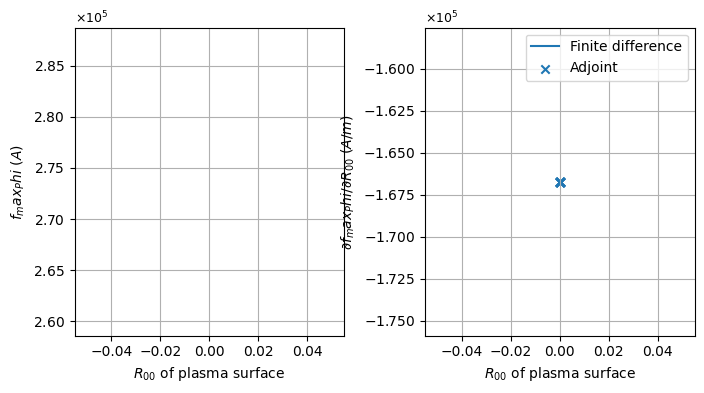

In [9]:
plot_taylor_test(
    plasma_dof_0_list_auglag,
    stacked_outdict_auglag, 
    metric='f_max_Phi',
    ylabel=r'$f_max_Phi$ ($A$)',
    dylabel=r'$\partial f_max_Phi/\partial R_{00}$ ($A/m$)',
)

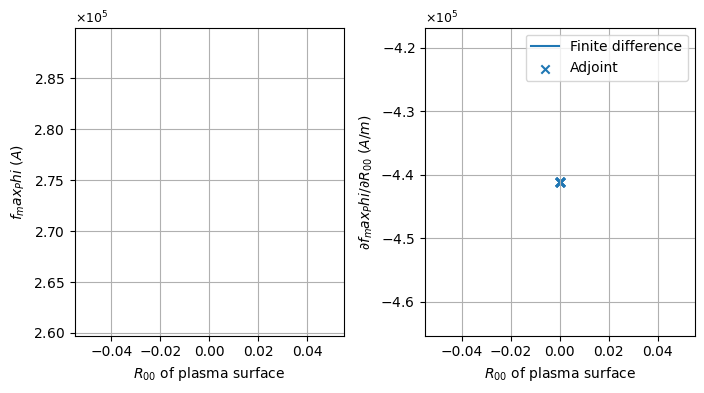

In [10]:
plot_taylor_test(
    plasma_dof_0_list_slsqp,
    stacked_outdict_slsqp, 
    metric='f_max_Phi',
    ylabel=r'$f_max_Phi$ ($A$)',
    dylabel=r'$\partial f_max_Phi/\partial R_{00}$ ($A/m$)',
)